In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(url)
print("Dataset sample:\n", df.head())

Dataset sample:
     mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  


In [ ]:
df.shape

(398, 9)

In [ ]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [ ]:
df.shape

(398, 9)

In [ ]:
print(df.isna().sum())

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [ ]:
df = df.dropna(subset=['horsepower'])

In [ ]:
df.shape

(392, 9)

In [ ]:
X = df[['horsepower']]
y = df['mpg']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
y_pred

array([29.38688782, 21.90741463, 30.85026301, 29.22429057, 26.62273468,
       28.41130436, 12.96456625, 28.41130436, 25.15935949, 32.63883268,
        9.71262139, 23.04559533, 15.4035249 , 28.41130436, 18.98066425,
       26.2975402 , 25.15935949, 28.41130436, 27.59831814, 26.2975402 ,
       25.15935949, 32.15104095, 29.54948506, 19.46845598, 29.7120823 ,
       25.97234571, 26.46013744, 23.53338706, 33.12662441, 28.24870711,
       17.02949733, 25.97234571, 20.2814422 , 28.5739016 , 16.21651112,
       29.7120823 , 17.84248355, 27.59831814, 17.84248355,  5.64769031,
       19.46845598, 28.41130436, 28.5739016 , 27.92351263, 16.5417056 ,
        5.64769031, 24.34637328, 29.38688782, 28.89909609, 29.22429057,
       15.72871939, 25.15935949, 25.97234571, 26.2975402 , 22.39520636,
       22.72040084, 22.72040084, 24.34637328, 25.15935949, 25.15935949,
        4.02171787, 25.97234571, 21.90741463, 26.2975402 , 25.15935949,
       27.4357209 , 26.2975402 , 29.22429057, 22.72040084,  8.41

In [ ]:
y_test

,mpg
79,26.0
276,21.6
248,36.1
56,26.0
393,27.0
...,...
366,17.6
83,28.0
115,15.0
3,16.0


In [ ]:
print("Coefficient (slope):", model.coef_[0])
print("Intercept:", model.intercept_)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

Coefficient (slope): -0.16259724322918453
Intercept: 40.606097600118346
Mean Squared Error: 22.153237123863413
R² Score: 0.5659681822256185


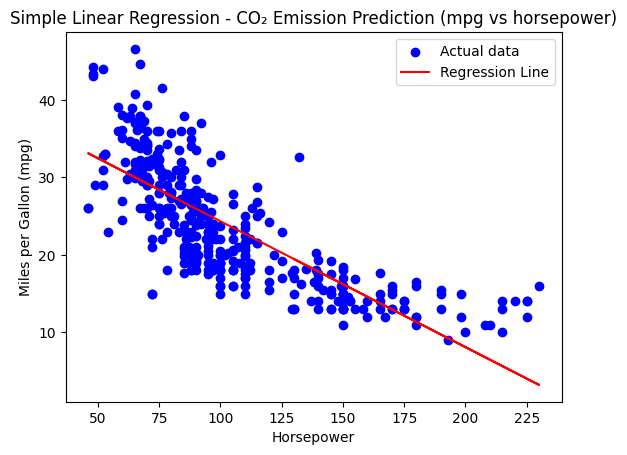

In [ ]:
plt.scatter(X, y, color='blue', label='Actual data')
plt.plot(X, model.predict(X), color='red', label='Regression Line')
plt.xlabel('Horsepower')
plt.ylabel('Miles per Gallon (mpg)')
plt.title('Simple Linear Regression - CO₂ Emission Prediction (mpg vs horsepower)')
plt.legend()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report,roc_auc_score

In [ ]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)
print("Shape X:", X.shape)
print("Target distribution:\n", y.value_counts())

Shape X: (569, 30)
Target distribution:
 1    357
0    212
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
X_train.shape

(455, 30)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
y_pred = model.predict(X_test_scaled)

In [ ]:
y_pred

array([0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1])

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9824561403508771

Confusion Matrix:
 [[41  1]
 [ 1 71]]

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

